# Practical 7: Sequence-Aware Recommendation Using RNN

## Aim

To build a sequence-aware recommender system on MovieLens Small using a **SimpleRNN** and evaluate **next-item prediction** performance.

The model learns:

\[
P(i_{t+1} \mid i_1, i_2, \ldots, i_t)
\]

The practical uses:

- chronological user interaction sequences
- movie-token vocabulary
- sequence truncation and padding
- embedding layer
- SimpleRNN
- softmax next-item prediction
- Top-1 Accuracy
- Hit Rate@5
- Hit Rate@10
- MRR@10
- NDCG@10


## 1. Mount Google Drive


In [ ]:
# 1. Mount Google Drive
# ------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")


# ------------------------------------------------------------


Mounted at /content/drive


## 2. Import libraries


In [ ]:
# 2. Import libraries
# ------------------------------------------------------------

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    SimpleRNN,
    Dense
)
from tensorflow.keras.preprocessing.sequence import (
    pad_sequences
)


# ------------------------------------------------------------


## 3. Settings


In [ ]:
# 3. Settings
# ------------------------------------------------------------

DATA_FOLDER = "/content/drive/MyDrive/RS/ML_Small"

RATINGS_FILE = os.path.join(
    DATA_FOLDER,
    "ratings.csv"
)

MOVIES_FILE = os.path.join(
    DATA_FOLDER,
    "movies.csv"
)

MAX_SEQUENCE_LENGTH = 10

EMBEDDING_DIM = 64
RNN_UNITS = 64

BATCH_SIZE = 128
EPOCHS = 10

TOP_N = 10
TOP_K_1 = 5
TOP_K_2 = 10

DEMO_USER_ID = 25

RANDOM_STATE = 42


# ------------------------------------------------------------


## 4. Reproducibility


In [ ]:
# 4. Reproducibility
# ------------------------------------------------------------

np.random.seed(
    RANDOM_STATE
)

tf.random.set_seed(
    RANDOM_STATE
)


# ------------------------------------------------------------


## 5. Load MovieLens Small


In [ ]:
# 5. Load MovieLens Small
# ------------------------------------------------------------

ratings = pd.read_csv(
    RATINGS_FILE
)

movies = pd.read_csv(
    MOVIES_FILE
)

required_rating_columns = {
    "userId",
    "movieId",
    "rating",
    "timestamp"
}

required_movie_columns = {
    "movieId",
    "title",
    "genres"
}

if not required_rating_columns.issubset(
    ratings.columns
):
    raise ValueError(
        "ratings.csv must contain "
        "userId, movieId, rating and timestamp."
    )

if not required_movie_columns.issubset(
    movies.columns
):
    raise ValueError(
        "movies.csv must contain "
        "movieId, title and genres."
    )

print("=" * 70)
print("MOVIELENS SMALL")
print("=" * 70)

print(
    "Ratings shape:",
    ratings.shape
)

print(
    "Movies shape :",
    movies.shape
)

print(
    "Users:",
    ratings["userId"].nunique()
)

print(
    "Movies:",
    ratings["movieId"].nunique()
)

print(
    "Ratings:",
    len(ratings)
)

display(
    ratings.head()
)

display(
    movies.head()
)


# ------------------------------------------------------------


MOVIELENS SMALL
Ratings shape: (100836, 4)
Movies shape : (9742, 3)
Users: 610
Movies: 9724
Ratings: 100836


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## 6. Sort interactions chronologically


In [ ]:
# 6. Sort interactions chronologically
# ------------------------------------------------------------

ratings_sorted = (
    ratings
    .sort_values(
        [
            "userId",
            "timestamp"
        ]
    )
    .reset_index(
        drop=True
    )
)

print(
    "\nChronologically sorted interactions:"
)

display(
    ratings_sorted.head(10)
)


# ------------------------------------------------------------



Chronologically sorted interactions:


,userId,movieId,rating,timestamp
0,1,804,4.0,964980499
1,1,1210,5.0,964980499
2,1,2018,5.0,964980523
3,1,2628,4.0,964980523
4,1,2826,4.0,964980523
5,1,3578,5.0,964980668
6,1,3617,4.0,964980683
7,1,3744,4.0,964980694
8,1,101,5.0,964980868
9,1,441,4.0,964980868


## 7. Build movie vocabulary


In [ ]:
# 7. Build movie vocabulary
#
# Token 0 is reserved for padding.
# Real movies begin from token 1.
# ------------------------------------------------------------

unique_movie_ids = np.sort(
    ratings_sorted[
        "movieId"
    ].unique()
)

movie_to_token = {
    movie_id: token
    for token, movie_id
    in enumerate(
        unique_movie_ids,
        start=1
    )
}

token_to_movie = {
    token: movie_id
    for movie_id, token
    in movie_to_token.items()
}

NUM_ITEMS = len(
    unique_movie_ids
)

VOCAB_SIZE = (
    NUM_ITEMS
    + 1
)

print(
    "\nNumber of modeled movies:",
    NUM_ITEMS
)

print(
    "Vocabulary size including padding:",
    VOCAB_SIZE
)


# ------------------------------------------------------------



Number of modeled movies: 9724
Vocabulary size including padding: 9725


## 8. Movie title lookup


In [ ]:
# 8. Movie title lookup
# ------------------------------------------------------------

movie_titles = (
    movies
    .drop_duplicates(
        "movieId"
    )
    .set_index(
        "movieId"
    )["title"]
)


# ------------------------------------------------------------


## 9. Build chronological user sequences


In [ ]:
# 9. Build chronological user sequences
# ------------------------------------------------------------

def build_user_sequences(
    ratings_frame
):
    """
    Convert timestamped interactions into ordered movie sequences.

    Parameters
    ----------
    ratings_frame:
        DataFrame containing userId, movieId and timestamp.

    Returns
    -------
    user_sequences:
        Dictionary:
        userId -> list of movie tokens in chronological order.
    """

    user_sequences = {}

    grouped = ratings_frame.groupby(
        "userId",
        sort=False
    )

    for user_id, group in grouped:

        movie_ids = (
            group[
                "movieId"
            ]
            .tolist()
        )

        tokens = [
            movie_to_token[
                movie_id
            ]
            for movie_id
            in movie_ids
        ]

        user_sequences[
            user_id
        ] = tokens

    return user_sequences


user_sequences = build_user_sequences(
    ratings_sorted
)

print(
    "\nNumber of user sequences:",
    len(
        user_sequences
    )
)


# ------------------------------------------------------------



Number of user sequences: 610


## 10. Keep users with at least 3 interactions


In [ ]:
# 10. Keep users with at least 3 interactions
#
# We need:
# earlier interactions -> training
# second-last          -> validation target
# last                 -> test target
# ------------------------------------------------------------

user_sequences = {
    user_id: sequence
    for user_id, sequence
    in user_sequences.items()
    if len(sequence) >= 3
}

print(
    "Users with at least 3 interactions:",
    len(
        user_sequences
    )
)


# ------------------------------------------------------------


Users with at least 3 interactions: 610


## 11. Show one user's temporal split


In [ ]:
# 11. Show one user's temporal split
# ------------------------------------------------------------

def token_sequence_to_titles(
    token_sequence
):
    """
    Convert a sequence of movie tokens to movie titles.
    """

    titles = []

    for token in token_sequence:

        movie_id = token_to_movie[
            token
        ]

        title = (
            movie_titles.loc[
                movie_id
            ]
            if movie_id
            in movie_titles.index
            else str(
                movie_id
            )
        )

        titles.append(
            title
        )

    return titles


if DEMO_USER_ID in user_sequences:

    demo_sequence = user_sequences[
        DEMO_USER_ID
    ]

else:

    DEMO_USER_ID = next(
        iter(
            user_sequences
        )
    )

    demo_sequence = user_sequences[
        DEMO_USER_ID
    ]


demo_train_sequence = (
    demo_sequence[:-2]
)

demo_validation_target = (
    demo_sequence[-2]
)

demo_test_target = (
    demo_sequence[-1]
)

print("\n" + "=" * 70)
print("EXAMPLE TEMPORAL SPLIT")
print("=" * 70)

print(
    "Demo user:",
    DEMO_USER_ID
)

print(
    "\nComplete sequence:"
)

for title in token_sequence_to_titles(
    demo_sequence
):
    print(
        " ->",
        title
    )

print(
    "\nTraining portion:"
)

for title in token_sequence_to_titles(
    demo_train_sequence
):
    print(
        " ->",
        title
    )

print(
    "\nValidation target:"
)

print(
    token_sequence_to_titles(
        [
            demo_validation_target
        ]
    )[0]
)

print(
    "\nTest target:"
)

print(
    token_sequence_to_titles(
        [
            demo_test_target
        ]
    )[0]
)


# ------------------------------------------------------------



EXAMPLE TEMPORAL SPLIT
Demo user: 25

Complete sequence:
 -> Lord of the Rings: The Return of the King, The (2003)
 -> Lord of the Rings: The Two Towers, The (2002)
 -> Lord of the Rings: The Fellowship of the Ring, The (2001)
 -> Matrix, The (1999)
 -> Inception (2010)
 -> Star Wars: Episode IV - A New Hope (1977)
 -> Schindler's List (1993)
 -> Dumb & Dumber (Dumb and Dumber) (1994)
 -> Avengers: Infinity War - Part I (2018)
 -> Blade Runner 2049 (2017)
 -> Incredibles 2 (2018)
 -> Wonder (2017)
 -> Up (2009)
 -> Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)
 -> Gladiator (2000)
 -> Dark Knight Rises, The (2012)
 -> Thor: Ragnarok (2017)
 -> Saving Private Ryan (1998)
 -> The Imitation Game (2014)
 -> Inglourious Basterds (2009)
 -> Iron Man (2008)
 -> WALL·E (2008)
 -> Dark Knight, The (2008)
 -> Shutter Island (2010)
 -> Three Billboards Outside Ebbing, Missouri (2017)
 -> Deadpool 2 (2018)

Training portion:
 -> Lord of the Rings: The Return of th

## 12. Create training examples from prefixes


In [ ]:
# 12. Create training examples from prefixes
#
# Example:
#
# [A]       -> B
# [A, B]    -> C
# [A, B, C] -> D
#
# For long histories, only the most recent
# MAX_SEQUENCE_LENGTH tokens are retained.
# ------------------------------------------------------------

def create_training_examples(
    user_sequences,
    max_sequence_length=MAX_SEQUENCE_LENGTH
):
    """
    Create training input/target pairs.

    For each user:
        training portion = sequence[:-2]

    Every prefix predicts the next item.
    """

    input_sequences = []
    targets = []

    for user_id, sequence in (
        user_sequences.items()
    ):

        train_sequence = (
            sequence[:-2]
        )

        if len(
            train_sequence
        ) < 2:
            continue

        for end_position in range(
            1,
            len(
                train_sequence
            )
        ):

            prefix = (
                train_sequence[
                    :end_position
                ]
            )

            target = (
                train_sequence[
                    end_position
                ]
            )

            prefix = (
                prefix[
                    -max_sequence_length:
                ]
            )

            input_sequences.append(
                prefix
            )

            targets.append(
                target
            )

    return (
        input_sequences,
        np.array(
            targets,
            dtype=np.int32
        )
    )


train_sequences_raw, y_train = (
    create_training_examples(
        user_sequences
    )
)

print(
    "\nTraining examples:",
    len(
        train_sequences_raw
    )
)


# ------------------------------------------------------------



Training examples: 99006


## 13. Pad training sequences


In [ ]:
# 13. Pad training sequences
#
# Pre-padding:
#
# [A, B, C]
#
# becomes:
#
# [0, 0, ..., A, B, C]
# ------------------------------------------------------------

X_train = pad_sequences(
    train_sequences_raw,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="pre",
    truncating="pre",
    value=0
)

print(
    "X_train shape:",
    X_train.shape
)

print(
    "y_train shape:",
    y_train.shape
)


# ------------------------------------------------------------


X_train shape: (99006, 10)
y_train shape: (99006,)


## 14. Build validation examples


In [ ]:
# 14. Build validation examples
#
# Input:
# all interactions before second-last item
#
# Target:
# second-last item
# ------------------------------------------------------------

def create_validation_data(
    user_sequences,
    max_sequence_length=MAX_SEQUENCE_LENGTH
):
    """
    Create one validation example per user.
    """

    sequences = []
    targets = []
    users = []

    for user_id, sequence in (
        user_sequences.items()
    ):

        input_sequence = (
            sequence[:-2]
        )

        target = (
            sequence[-2]
        )

        if len(
            input_sequence
        ) == 0:
            continue

        input_sequence = (
            input_sequence[
                -max_sequence_length:
            ]
        )

        sequences.append(
            input_sequence
        )

        targets.append(
            target
        )

        users.append(
            user_id
        )

    X_val = pad_sequences(
        sequences,
        maxlen=max_sequence_length,
        padding="pre",
        truncating="pre",
        value=0
    )

    y_val = np.array(
        targets,
        dtype=np.int32
    )

    return (
        X_val,
        y_val,
        users
    )


X_val, y_val, val_users = (
    create_validation_data(
        user_sequences
    )
)

print(
    "\nValidation examples:",
    len(
        y_val
    )
)


# ------------------------------------------------------------



Validation examples: 610


## 15. Build the SimpleRNN model


In [ ]:
# 15. Build the SimpleRNN model
#
# Architecture:
#
# movie token
#    ↓
# Embedding
#    ↓
# SimpleRNN
#    ↓
# Dense + Softmax
#    ↓
# Probability of every possible next movie
# ------------------------------------------------------------

def build_rnn_model(
    vocab_size,
    embedding_dim=EMBEDDING_DIM,
    rnn_units=RNN_UNITS
):
    """
    Build a next-item prediction model.
    """

    model = Sequential([
        Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            mask_zero=True
        ),

        SimpleRNN(
            rnn_units
        ),

        Dense(
            vocab_size,
            activation="softmax"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=[
            "sparse_categorical_accuracy"
        ]
    )

    return model


model = build_rnn_model(
    vocab_size=VOCAB_SIZE
)

print("\n" + "=" * 70)
print("RNN MODEL")
print("=" * 70)

model.summary()


# ------------------------------------------------------------



RNN MODEL


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 16. Train the model


In [ ]:
# 16. Train the model
# ------------------------------------------------------------

history = model.fit(
    X_train,
    y_train,
    validation_data=(
        X_val,
        y_val
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)


# ------------------------------------------------------------


Epoch 1/10
774/774 ━━━━━━━━━━━━━━━━━━━━ 60s 75ms/step - loss: 8.1450 - sparse_categorical_accuracy: 0.0026 - val_loss: 8.0399 - val_sparse_categorical_accuracy: 0.0082
Epoch 2/10
774/774 ━━━━━━━━━━━━━━━━━━━━ 52s 67ms/step - loss: 7.8066 - sparse_categorical_accuracy: 0.0029 - val_loss: 8.0180 - val_sparse_categorical_accuracy: 0.0049
Epoch 3/10
774/774 ━━━━━━━━━━━━━━━━━━━━ 53s 69ms/step - loss: 7.6546 - sparse_categorical_accuracy: 0.0038 - val_loss: 7.9964 - val_sparse_categorical_accuracy: 0.0033
Epoch 4/10
774/774 ━━━━━━━━━━━━━━━━━━━━ 79s 65ms/step - loss: 7.4685 - sparse_categorical_accuracy: 0.0055 - val_loss: 7.9192 - val_sparse_categorical_accuracy: 0.0049
Epoch 5/10
774/774 ━━━━━━━━━━━━━━━━━━━━ 45s 58ms/step - loss: 7.2594 - sparse_categorical_accuracy: 0.0081 - val_loss: 7.8464 - val_sparse_categorical_accuracy: 0.0049
Epoch 6/10
774/774 ━━━━━━━━━━━━━━━━━━━━ 49s 64ms/step - loss: 7.0688 - sparse_categorical_accuracy: 0.0108 - val_loss: 7.8609 - val_sparse_categorical_accuracy:

## 17. Plot training and validation loss


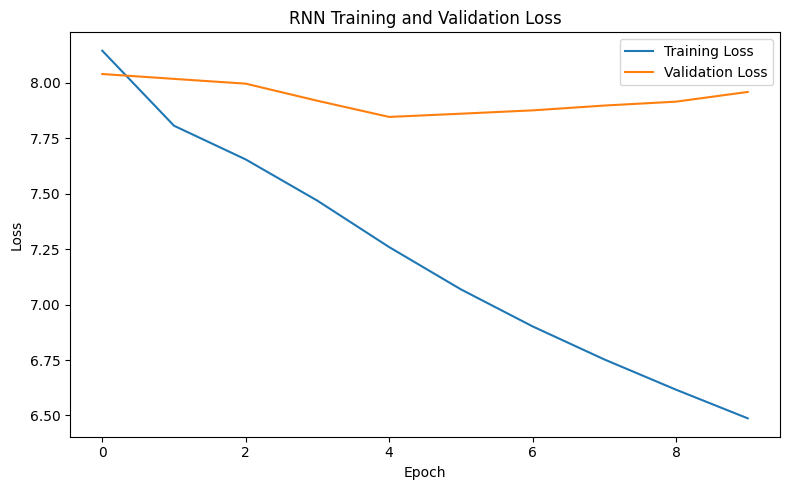

In [ ]:
# 17. Plot training and validation loss
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history.history[
        "loss"
    ],
    label="Training Loss"
)

plt.plot(
    history.history[
        "val_loss"
    ],
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "RNN Training and Validation Loss"
)

plt.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------


## 18. Prepare one sequence for prediction


In [ ]:
# 18. Prepare one sequence for prediction
# ------------------------------------------------------------

def prepare_sequence(
    token_sequence,
    max_sequence_length=MAX_SEQUENCE_LENGTH
):
    """
    Truncate to the latest interactions and pad to fixed length.
    """

    recent = token_sequence[
        -max_sequence_length:
    ]

    prepared = pad_sequences(
        [
            recent
        ],
        maxlen=max_sequence_length,
        padding="pre",
        truncating="pre",
        value=0
    )

    return prepared


# ------------------------------------------------------------


## 19. Predict Top-N next items


In [ ]:
# 19. Predict Top-N next items
# ------------------------------------------------------------

def predict_next_items(
    model,
    history_tokens,
    top_n=TOP_N,
    exclude_seen=True
):
    """
    Predict Top-N next movies from one user's interaction history.

    Parameters
    ----------
    model:
        Trained Keras model.

    history_tokens:
        Chronological token sequence used as context.

    top_n:
        Number of recommendations.

    exclude_seen:
        If True, movies already in the user's history are masked.

    Returns
    -------
    DataFrame with rank, movieId, title and probability.
    """

    prepared = prepare_sequence(
        history_tokens
    )

    probabilities = (
        model.predict(
            prepared,
            verbose=0
        )[0]
    )

    # Token 0 is padding, never a recommendation.
    probabilities[0] = -np.inf

    if exclude_seen:

        seen_tokens = np.unique(
            history_tokens
        )

        probabilities[
            seen_tokens
        ] = -np.inf

    valid_tokens = np.where(
        np.isfinite(
            probabilities
        )
    )[0]

    n_keep = min(
        top_n,
        len(
            valid_tokens
        )
    )

    valid_scores = probabilities[
        valid_tokens
    ]

    top_local = np.argpartition(
        valid_scores,
        -n_keep
    )[-n_keep:]

    top_tokens = valid_tokens[
        top_local
    ]

    top_tokens = top_tokens[
        np.argsort(
            probabilities[
                top_tokens
            ]
        )[::-1]
    ]

    rows = []

    for rank, token in enumerate(
        top_tokens,
        start=1
    ):

        movie_id = token_to_movie[
            int(
                token
            )
        ]

        title = (
            movie_titles.loc[
                movie_id
            ]
            if movie_id
            in movie_titles.index
            else str(
                movie_id
            )
        )

        rows.append({
            "Rank": rank,
            "movieId": movie_id,
            "Movie": title,
            "Probability": float(
                probabilities[
                    token
                ]
            )
        })

    return pd.DataFrame(
        rows
    )


# ------------------------------------------------------------


## 20. Demo next-item recommendations


In [ ]:
# 20. Demo next-item recommendations
#
# For final test-style prediction, the context contains every
# interaction before the user's last item.
# ------------------------------------------------------------

demo_test_context = (
    demo_sequence[:-1]
)

demo_predictions = predict_next_items(
    model,
    demo_test_context,
    top_n=TOP_N,
    exclude_seen=True
)

print("\n" + "=" * 70)

print(
    f"TOP {TOP_N} NEXT-ITEM PREDICTIONS "
    f"FOR USER {DEMO_USER_ID}"
)

print("=" * 70)

display(
    demo_predictions
)

print(
    "\nActual next movie:"
)

print(
    token_sequence_to_titles(
        [
            demo_test_target
        ]
    )[0]
)


# ------------------------------------------------------------



TOP 10 NEXT-ITEM PREDICTIONS FOR USER 25


,Rank,movieId,Movie,Probability
0,1,48780,"Prestige, The (2006)",0.015794
1,2,106782,"Wolf of Wall Street, The (2013)",0.011592
2,3,109487,Interstellar (2014),0.011547
3,4,293,Léon: The Professional (a.k.a. The Professiona...,0.011294
4,5,7361,Eternal Sunshine of the Spotless Mind (2004),0.010689
5,6,33794,Batman Begins (2005),0.010051
6,7,7438,Kill Bill: Vol. 2 (2004),0.008939
7,8,48516,"Departed, The (2006)",0.008568
8,9,4306,Shrek (2001),0.008049
9,10,356,Forrest Gump (1994),0.007504



Actual next movie:
Deadpool 2 (2018)


## 21. Visualize Top-N next-item probabilities


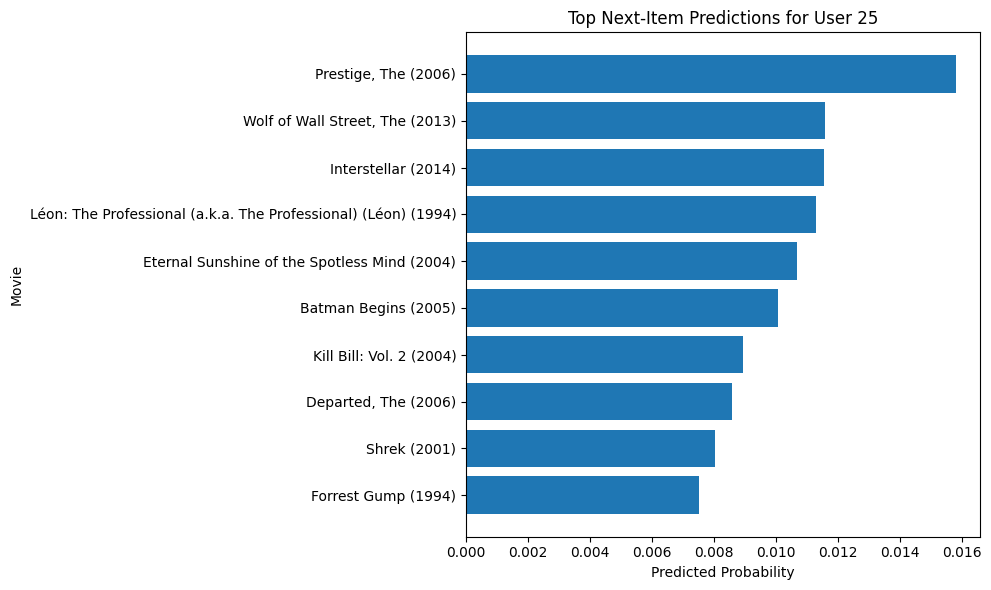

In [ ]:
# 21. Visualize Top-N next-item probabilities
# ------------------------------------------------------------

if not demo_predictions.empty:

    plot_data = (
        demo_predictions
        .sort_values(
            "Probability",
            ascending=True
        )
    )

    plt.figure(
        figsize=(10, 6)
    )

    plt.barh(
        plot_data[
            "Movie"
        ],
        plot_data[
            "Probability"
        ]
    )

    plt.xlabel(
        "Predicted Probability"
    )

    plt.ylabel(
        "Movie"
    )

    plt.title(
        f"Top Next-Item Predictions "
        f"for User {DEMO_USER_ID}"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------


## 22. Create test contexts


In [ ]:
# 22. Create test contexts
#
# Input:
# every interaction before the last item
#
# Target:
# last item
# ------------------------------------------------------------

def create_test_data(
    user_sequences,
    max_sequence_length=MAX_SEQUENCE_LENGTH
):
    """
    Create one next-item test example per user.
    """

    sequences = []
    targets = []
    users = []
    full_histories = []

    for user_id, sequence in (
        user_sequences.items()
    ):

        history_tokens = (
            sequence[:-1]
        )

        target = (
            sequence[-1]
        )

        if len(
            history_tokens
        ) == 0:
            continue

        input_sequence = (
            history_tokens[
                -max_sequence_length:
            ]
        )

        sequences.append(
            input_sequence
        )

        targets.append(
            target
        )

        users.append(
            user_id
        )

        full_histories.append(
            history_tokens
        )

    X_test = pad_sequences(
        sequences,
        maxlen=max_sequence_length,
        padding="pre",
        truncating="pre",
        value=0
    )

    y_test = np.array(
        targets,
        dtype=np.int32
    )

    return (
        X_test,
        y_test,
        users,
        full_histories
    )


(
    X_test,
    y_test,
    test_users,
    test_histories
) = create_test_data(
    user_sequences
)

print(
    "\nTest examples:",
    len(
        y_test
    )
)


# ------------------------------------------------------------



Test examples: 610


## 23. Predict probability distributions for all test users


In [ ]:
# 23. Predict probability distributions for all test users
# ------------------------------------------------------------

test_probabilities = model.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=1
)


# ------------------------------------------------------------


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


## 24. Evaluate next-item prediction


In [ ]:
# 24. Evaluate next-item prediction
#
# Metrics:
# Top-1 Accuracy
# HR@5
# HR@10
# MRR@10
# NDCG@10
# ------------------------------------------------------------

def evaluate_next_item(
    probability_matrix,
    targets,
    histories,
    top_k_1=TOP_K_1,
    top_k_2=TOP_K_2
):
    """
    Evaluate true next-item ranks.

    Already-seen movie tokens are masked before ranking because
    MovieLens users normally rate a movie only once.
    """

    rows = []

    for index in range(
        len(
            targets
        )
    ):

        probabilities = (
            probability_matrix[
                index
            ]
            .copy()
        )

        target_token = int(
            targets[
                index
            ]
        )

        history_tokens = np.unique(
            histories[
                index
            ]
        )

        # Padding token cannot be recommended.
        probabilities[0] = -np.inf

        # Remove previously seen movies.
        probabilities[
            history_tokens
        ] = -np.inf

        target_score = probabilities[
            target_token
        ]

        if not np.isfinite(
            target_score
        ):
            rank = None

        else:

            rank = (
                int(
                    np.sum(
                        probabilities
                        > target_score
                    )
                )
                + 1
            )

        top1 = int(
            rank == 1
        )

        hit_5 = int(
            rank is not None
            and rank <= top_k_1
        )

        hit_10 = int(
            rank is not None
            and rank <= top_k_2
        )

        rr_10 = (
            1.0 / rank
            if hit_10
            else 0.0
        )

        ndcg_10 = (
            1.0
            / np.log2(
                rank + 1
            )
            if hit_10
            else 0.0
        )

        rows.append({
            "Target Token": target_token,
            "Rank": rank,
            "Top-1 Correct": top1,
            f"Hit@{top_k_1}": hit_5,
            f"Hit@{top_k_2}": hit_10,
            f"RR@{top_k_2}": rr_10,
            f"NDCG@{top_k_2}": ndcg_10
        })

    results = pd.DataFrame(
        rows
    )

    metrics = {
        "Top-1 Accuracy": results[
            "Top-1 Correct"
        ].mean(),

        f"Hit Rate@{top_k_1}": results[
            f"Hit@{top_k_1}"
        ].mean(),

        f"Hit Rate@{top_k_2}": results[
            f"Hit@{top_k_2}"
        ].mean(),

        f"MRR@{top_k_2}": results[
            f"RR@{top_k_2}"
        ].mean(),

        f"NDCG@{top_k_2}": results[
            f"NDCG@{top_k_2}"
        ].mean()
    }

    return (
        results,
        metrics
    )


evaluation_results, metrics = (
    evaluate_next_item(
        test_probabilities,
        y_test,
        test_histories
    )
)


# ------------------------------------------------------------


## 25. Show evaluation metrics


In [ ]:
# 25. Show evaluation metrics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NEXT-ITEM PREDICTION EVALUATION")
print("=" * 70)

for metric_name, value in (
    metrics.items()
):

    print(
        f"{metric_name}: "
        f"{value:.4f}"
    )


metric_table = pd.DataFrame({
    "Metric": list(
        metrics.keys()
    ),
    "Value": list(
        metrics.values()
    )
})

display(
    metric_table
)


# ------------------------------------------------------------



NEXT-ITEM PREDICTION EVALUATION
Top-1 Accuracy: 0.0016
Hit Rate@5: 0.0279
Hit Rate@10: 0.0541
MRR@10: 0.0139
NDCG@10: 0.0232


,Metric,Value
0,Top-1 Accuracy,0.001639
1,Hit Rate@5,0.027869
2,Hit Rate@10,0.054098
3,MRR@10,0.013936
4,NDCG@10,0.023197


## 26. Add user and movie information to test results


In [ ]:
# 26. Add user and movie information to test results
# ------------------------------------------------------------

evaluation_results[
    "userId"
] = test_users

evaluation_results[
    "Target movieId"
] = [
    token_to_movie[
        int(
            token
        )
    ]
    for token in y_test
]

evaluation_results[
    "Target Movie"
] = [
    (
        movie_titles.loc[
            movie_id
        ]
        if movie_id
        in movie_titles.index
        else str(
            movie_id
        )
    )
    for movie_id
    in evaluation_results[
        "Target movieId"
    ]
]

print(
    "\nSample test results"
)

display(
    evaluation_results[
        [
            "userId",
            "Target movieId",
            "Target Movie",
            "Rank",
            "Top-1 Correct",
            f"Hit@{TOP_K_1}",
            f"Hit@{TOP_K_2}",
            f"RR@{TOP_K_2}",
            f"NDCG@{TOP_K_2}"
        ]
    ].head(15)
)


# ------------------------------------------------------------



Sample test results


,userId,Target movieId,Target Movie,Rank,Top-1 Correct,Hit@5,Hit@10,RR@10,NDCG@10
0,1,2492,20 Dates (1998),3191,0,0,0,0.0,0.0
1,2,80489,"Town, The (2010)",208,0,0,0,0.0,0.0
2,3,2424,You've Got Mail (1998),1092,0,0,0,0.0,0.0
3,4,4246,Bridget Jones's Diary (2001),96,0,0,0,0.0,0.0
4,5,474,In the Line of Fire (1993),14,0,0,0,0.0,0.0
5,6,780,Independence Day (a.k.a. ID4) (1996),4384,0,0,0,0.0,0.0
6,7,49286,"Holiday, The (2006)",704,0,0,0,0.0,0.0
7,8,235,Ed Wood (1994),33,0,0,0,0.0,0.0
8,9,5962,Body of Evidence (1993),8324,0,0,0,0.0,0.0
9,10,1088,Dirty Dancing (1987),1520,0,0,0,0.0,0.0


## 27. Visualize distribution of true next-item ranks


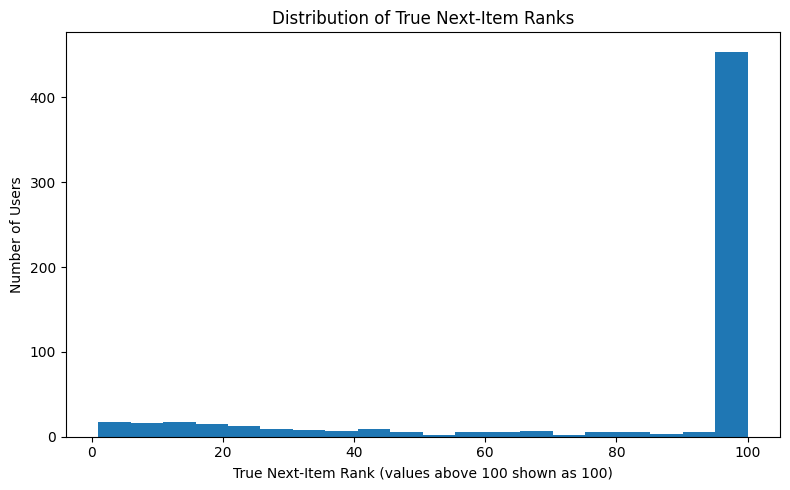

In [ ]:
# 27. Visualize distribution of true next-item ranks
# ------------------------------------------------------------

rank_values = (
    evaluation_results[
        "Rank"
    ]
    .dropna()
)

if len(
    rank_values
) > 0:

    # To keep the plot readable, display ranks up to 100.
    clipped_ranks = np.minimum(
        rank_values.to_numpy(
            dtype=float
        ),
        100
    )

    plt.figure(
        figsize=(8, 5)
    )

    plt.hist(
        clipped_ranks,
        bins=20
    )

    plt.xlabel(
        "True Next-Item Rank "
        "(values above 100 shown as 100)"
    )

    plt.ylabel(
        "Number of Users"
    )

    plt.title(
        "Distribution of True Next-Item Ranks"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------


## 28. Visualize evaluation metrics


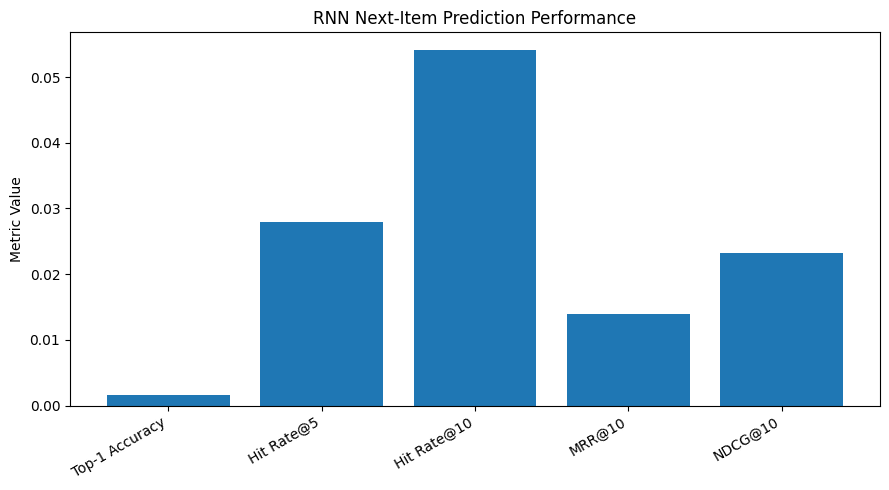

In [ ]:
# 28. Visualize evaluation metrics
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    metric_table[
        "Metric"
    ],
    metric_table[
        "Value"
    ]
)

plt.ylabel(
    "Metric Value"
)

plt.title(
    "RNN Next-Item Prediction Performance"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
